# BD532 Lab 1.1: ML Pipeline ด้วย scikit-learn

**เวลา:** 90 นาที · **เครื่องมือ:** Google Colab · **ต่อด้วย:** Lab 1.2 Publish โมเดลเป็น API (ทำใน GitHub Codespaces)

อ้างอิงจาก [How to Improve Machine Learning Code Quality with Scikit-learn Pipeline and ColumnTransformer (freeCodeCamp)](https://www.freecodecamp.org/news/machine-learning-pipeline/) โดย Yannawut Kimnaruk ปรับโค้ดให้ใช้กับ scikit-learn รุ่นปัจจุบัน

**โจทย์:** ข้อมูล HR Analytics: Job Change of Data Scientists บริษัทหนึ่งเปิดคอร์สอบรม Data Science และอยากรู้ว่าผู้เข้าอบรมคนใดกำลังมองหางานใหม่ (`target = 1`)

**เมื่อจบ Lab นี้ จะได้**
- pipeline ที่รวมการเตรียมข้อมูลและโมเดลไว้ใน object เดียว รับข้อมูลดิบได้ทันที
- ไฟล์ `bd532_lab1_artifacts.zip` (มี `features.py`, `model/pipe.joblib`, `model/metadata.json`) สำหรับนำไปทำ API ใน Lab 1.2

| ส่วน | เนื้อหา | เวลา |
|---|---|---|
| 0 | เตรียม Colab และดาวน์โหลดข้อมูล | 5 นาที |
| 1 | สำรวจข้อมูล | 15 นาที |
| 2 | สร้าง pipeline: `Pipeline`, `ColumnTransformer`, custom transformer | 20 นาที |
| 3 | เทรนและประเมิน เทียบกับ baseline | 20 นาที |
| 4 | `GridSearchCV` เลือก preprocessing และโมเดล | 20 นาที |
| 5 | บันทึก pipeline และดาวน์โหลดไฟล์ | 10 นาที |

**วิธีใช้ Colab:** คลิกที่เซลล์โค้ดแล้วกด `Shift + Enter` เพื่อรันและไปเซลล์ถัดไป รันทีละเซลล์ **ตามลำดับจากบนลงล่าง** อ่านคำอธิบายก่อนรันทุกครั้ง ถ้าเซลล์ใดขึ้น error ให้แก้แล้วรันเซลล์นั้นใหม่

> ⚠️ ก่อนเริ่ม ให้กด **File → Save a copy in Drive** เพื่อบันทึกสำเนาของตัวเอง ไม่เช่นนั้นงานที่แก้จะหายเมื่อปิดหน้า

---
## ส่วนที่ 0: เตรียม Colab และดาวน์โหลดข้อมูล

ติดตั้ง scikit-learn **เวอร์ชันเดียวกับที่ใช้ใน Lab 1.2** เพราะไฟล์โมเดลที่บันทึกจาก scikit-learn เวอร์ชันหนึ่ง อาจโหลดไม่ได้หรือทำงานผิดในเวอร์ชันอื่น

> ถ้า Colab ขึ้นข้อความให้ **Restart session** หลังติดตั้ง ให้กด Restart แล้วเริ่มรันจากเซลล์ถัดไป (ไม่ต้องรันเซลล์ติดตั้งซ้ำ)

In [1]:
!pip install -q scikit-learn==1.9.1

In [2]:
import sys

import numpy as np
import pandas as pd
import sklearn

print("Python      :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)   # ต้องเป็น 1.9.1
print("pandas      :", pd.__version__)

Python      : 3.13.18
scikit-learn: 1.9.1
pandas      : 2.2.3


ดาวน์โหลดข้อมูลจาก [GitHub ของผู้เขียนบทความ](https://github.com/Yannawut/ML_Pipeline) (ต้นฉบับมาจาก Kaggle แต่ดาวน์โหลดจาก GitHub ได้โดยไม่ต้องล็อกอิน)

In [3]:
!mkdir -p data model
!wget -q -O data/aug_train.csv https://raw.githubusercontent.com/Yannawut/ML_Pipeline/main/aug_train.csv
!wc -l data/aug_train.csv

19159 data/aug_train.csv


✅ **Checkpoint 0:** scikit-learn เป็นเวอร์ชัน `1.9.1` และไฟล์ข้อมูลมี `19159` บรรทัด (ข้อมูล 19,158 แถว + header)

---
## ส่วนที่ 1: สำรวจข้อมูล

ดูข้อมูลก่อนออกแบบ pipeline เสมอ เพราะสิ่งที่เห็นจะบอกว่าต้องมีขั้นตอนอะไรบ้าง

In [4]:
df = pd.read_csv("data/aug_train.csv")
print("ขนาดข้อมูล (แถว, คอลัมน์):", df.shape)
df.head()

ขนาดข้อมูล (แถว, คอลัมน์): (19158, 14)


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


คอลัมน์ที่ใช้เป็น feature แบ่งเป็น 2 กลุ่ม (ไม่ใช้ `enrollee_id` ซึ่งเป็นรหัส และ `city` ซึ่งมีค่าต่างกันมากเกินไป)

| กลุ่ม | คอลัมน์ |
|---|---|
| ตัวเลข (รวมข้อความที่มีลำดับ ซึ่งจะแปลงเป็นตัวเลข) | `city_development_index`, `relevent_experience`, `experience`, `last_new_job`, `training_hours` |
| ประเภท (ไม่มีลำดับ) | `gender`, `enrolled_university`, `education_level`, `major_discipline`, `company_size`, `company_type` |

In [5]:
NUM_COLS = ["city_development_index", "relevent_experience", "experience", "last_new_job", "training_hours"]
CAT_COLS = ["gender", "enrolled_university", "education_level", "major_discipline", "company_size", "company_type"]

print("จำนวนค่าว่างในแต่ละคอลัมน์:")
df[NUM_COLS + CAT_COLS].isna().sum().sort_values(ascending=False)

จำนวนค่าว่างในแต่ละคอลัมน์:


,0
company_type,6140
company_size,5938
gender,4508
major_discipline,2813
education_level,460
last_new_job,423
enrolled_university,386
experience,65
city_development_index,0
relevent_experience,0


In [6]:
print("สัดส่วนของ target (1 = กำลังหางานใหม่):")
df["target"].value_counts(normalize=True).round(3)

สัดส่วนของ target (1 = กำลังหางานใหม่):


,proportion
target,
0.0,0.751
1.0,0.249


In [7]:
for col in ["relevent_experience", "experience", "last_new_job", "gender", "company_type"]:
    print(f"{col}: {sorted(df[col].dropna().unique().tolist())}")

relevent_experience: ['Has relevent experience', 'No relevent experience']
experience: ['1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '3', '4', '5', '6', '7', '8', '9', '<1', '>20']
last_new_job: ['1', '2', '3', '4', '>4', 'never']
gender: ['Female', 'Male', 'Other']
company_type: ['Early Stage Startup', 'Funded Startup', 'NGO', 'Other', 'Public Sector', 'Pvt Ltd']


### คำถามชวนคิด (ตอบในใจก่อนเปิดดูคำตอบ)

<details>
<summary>1. คอลัมน์ใดมีค่าว่างมาก และ pipeline ต้องมีขั้นตอนอะไร</summary>

`company_type` ว่าง 32%, `company_size` 31%, `gender` 24% ต้องมีขั้น **เติมค่าว่าง** (`SimpleImputer`) ถ้าลบแถวที่มีค่าว่างทิ้ง จะเสียข้อมูลเกินครึ่ง
</details>

<details>
<summary>2. ทำไม <code>experience</code> ไม่ควรใช้ one-hot encoding</summary>

ค่าของ `experience` เป็นข้อความแต่ **มีลำดับ** (`<1` < `1` < ... < `20` < `>20`) ควรแปลงเป็นตัวเลขที่รักษาลำดับไว้ (`<1` → 0, `>20` → 21) ส่วน one-hot จะทำให้โมเดลไม่รู้ว่า 15 ปีมากกว่า 2 ปี
</details>

<details>
<summary>3. target = 1 มีเพียง 25% ส่งผลอย่างไรต่อการวัดผล</summary>

ข้อมูล **ไม่สมดุล** ถ้าทายว่า "ไม่เปลี่ยนงาน" ทุกคนก็ได้ accuracy 75% แล้ว accuracy อย่างเดียวจึงหลอกได้ ต้องเทียบกับ baseline และดู metric อื่น เช่น recall และ ROC AUC
</details>

✅ **Checkpoint 1:** บอกได้ว่าคอลัมน์ใดมีค่าว่างมากที่สุด และทำไม `experience` ไม่ควรใช้ one-hot

---
## ส่วนที่ 2: สร้าง pipeline

### ทำไมต้องใช้ Pipeline

| ถ้าเขียนการเตรียมข้อมูลแยกเป็นขั้นๆ เอง | ถ้าใช้ `Pipeline` |
|---|---|
| ต้องเรียก `fit`/`transform` ทีละขั้น ทั้งกับ train และ test เสี่ยงลืมหรือสลับลำดับ | เรียก `fit` และ `predict` ครั้งเดียว ทุกขั้นทำตามลำดับเสมอ |
| เผลอ fit imputer หรือ scaler กับข้อมูลทั้งหมด ทำให้ข้อมูล test รั่วเข้าไปตอนเทรน (**data leakage**) | ทุกขั้นเรียนรู้จากข้อมูลที่ส่งให้ `fit` เท่านั้น |
| ตอน deploy ต้องเขียนการเตรียมข้อมูลซ้ำใน API มักได้ผลไม่ตรงกับตอนเทรน (**training/serving skew**) | บันทึก pipeline ทั้งชุดเป็นไฟล์เดียว API ใช้การเตรียมข้อมูลชุดเดียวกับตอนเทรน |
| ปรับ hyperparameter ได้เฉพาะของโมเดล | ค้นหาทั้ง hyperparameter ทางเลือกของการเตรียมข้อมูล และชนิดโมเดลได้ในครั้งเดียว |

| ส่วนประกอบ | ใช้เมื่อ | ตัวอย่างใน Lab นี้ |
|---|---|---|
| `Pipeline` | ต่อหลายขั้น **ตามลำดับ** | เติมค่าว่าง → ปรับสเกล |
| `ColumnTransformer` | เตรียมข้อมูล **ต่างกัน** กับคอลัมน์คนละกลุ่ม แล้วนำผลมาต่อกัน | ตัวเลขใช้ `num` pipeline, ประเภทใช้ `cat` pipeline |
| Custom transformer | ต้องการขั้นตอนที่ scikit-learn ไม่มีให้ | `OrdinalMapper` แปลง `">20"` เป็น `21` |

### เขียนส่วนประกอบของ pipeline ลงไฟล์ `features.py`

เซลล์ด้านล่างใช้คำสั่ง `%%writefile` เขียนโค้ดลง **ไฟล์** แทนการรันในโน้ตบุ๊กโดยตรง เพราะ:

- เมื่อบันทึก pipeline ด้วย `joblib` ไฟล์จะจำว่า class `OrdinalMapper` อยู่ใน module ใด ถ้าประกาศ class ไว้ในโน้ตบุ๊ก API ใน Lab 1.2 จะโหลดโมเดลไม่ได้ (error `Can't get attribute 'OrdinalMapper'`)
- Lab 1.2 จะใช้ไฟล์ `features.py` นี้ไฟล์เดียวกัน การเตรียมข้อมูลจึงมีอยู่ที่เดียว

In [8]:
%%writefile features.py
"""ส่วนประกอบของ ML pipeline ที่ใช้ร่วมกันทั้งตอนเทรน (Lab 1.1) และตอนให้บริการ API (Lab 1.2)"""
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

# คอลัมน์ตัวเลข (รวมคอลัมน์ข้อความที่มีลำดับ ซึ่งจะถูกแปลงเป็นตัวเลขก่อน)
NUM_COLS = ["city_development_index", "relevent_experience", "experience", "last_new_job", "training_hours"]
# คอลัมน์ประเภท (categorical) ที่ไม่มีลำดับ
CAT_COLS = ["gender", "enrolled_university", "education_level", "major_discipline", "company_size", "company_type"]
FEATURES = NUM_COLS + CAT_COLS
TARGET = "target"

# ตารางแปลงค่าข้อความที่มีลำดับเป็นตัวเลข
ORDINAL_MAPS = {
    "relevent_experience": {"Has relevent experience": 1, "No relevent experience": 0},
    "experience": {"<1": 0, **{str(i): i for i in range(1, 21)}, ">20": 21},
    "last_new_job": {"never": 0, "1": 1, "2": 2, "3": 3, "4": 4, ">4": 5},
}


class OrdinalMapper(BaseEstimator, TransformerMixin):
    """Custom transformer: แปลงคอลัมน์ข้อความที่มีลำดับ (เช่น '<1', '5', '>20') เป็นตัวเลข

    ค่าที่ไม่อยู่ในตารางหรือค่าว่างจะกลายเป็น NaN แล้วให้ SimpleImputer ในขั้นถัดไปเติมค่า
    """

    def fit(self, X, y=None):
        return self  # ไม่ต้องเรียนรู้อะไรจากข้อมูล

    def transform(self, X):
        X = X.copy()
        for col, mapping in ORDINAL_MAPS.items():
            X[col] = X[col].map(mapping).astype(float)
        return X


def build_pipeline(model=None):
    """สร้าง pipeline: แปลงค่าที่มีลำดับ → เตรียมคอลัมน์ตัวเลขและประเภทแยกกัน → โมเดล"""
    num_pipeline = Pipeline(steps=[
        ("impute", SimpleImputer(strategy="mean")),
        ("scale", MinMaxScaler()),
    ])
    cat_pipeline = Pipeline(steps=[
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    col_trans = ColumnTransformer(
        transformers=[
            ("num", num_pipeline, NUM_COLS),
            ("cat", cat_pipeline, CAT_COLS),
        ],
        remainder="drop",
    )
    if model is None:
        model = LogisticRegression(max_iter=1000, random_state=0)
    return Pipeline(steps=[
        ("encode", OrdinalMapper()),
        ("col_trans", col_trans),
        ("model", model),
    ])

Writing features.py


| ส่วนในโค้ด | หน้าที่ |
|---|---|
| `ORDINAL_MAPS` | ตารางแปลงข้อความที่มีลำดับเป็นตัวเลข เช่น `"<1"` → `0`, `">20"` → `21`, `"never"` → `0` |
| `OrdinalMapper` | custom transformer ที่ใช้ตารางด้านบน สืบทอดจาก `BaseEstimator` และ `TransformerMixin` จึงใส่ใน pipeline และใช้กับ `GridSearchCV` ได้ |
| `num_pipeline` | คอลัมน์ตัวเลข: เติมค่าว่างด้วยค่าเฉลี่ย → ปรับสเกลเป็น 0–1 |
| `cat_pipeline` | คอลัมน์ประเภท: เติมค่าว่างด้วยค่าที่พบบ่อยที่สุด → one-hot (`handle_unknown="ignore"` ทำให้ค่าใหม่ที่ไม่เคยเห็นตอนเทรนไม่ทำให้ระบบพัง) |
| `ColumnTransformer` | ส่งแต่ละกลุ่มคอลัมน์เข้า pipeline ของตัวเอง แล้วต่อผลเข้าด้วยกัน คอลัมน์ที่ไม่ได้ระบุถูกทิ้ง (`remainder="drop"`) |
| `build_pipeline(model)` | ประกอบทุกขั้นเป็น pipeline เดียว: `encode` → `col_trans` → `model` |

import ไฟล์ที่เพิ่งเขียน แล้วดูแผนภาพของ pipeline (คลิกที่กล่องในแผนภาพเพื่อดูรายละเอียดของแต่ละขั้น)

In [9]:
from sklearn import set_config

from features import CAT_COLS, FEATURES, NUM_COLS, TARGET, OrdinalMapper, build_pipeline

set_config(display="diagram")
pipe = build_pipeline()
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encode', ...), ('col_trans', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If 

### ดูว่าแต่ละขั้นทำอะไรกับข้อมูล

**ขั้น `encode` (`OrdinalMapper`):** คอลัมน์ข้อความที่มีลำดับกลายเป็นตัวเลข ค่าว่างยังเป็น `NaN` อยู่ (ขั้นถัดไปจะเติมให้)

In [10]:
sample = df[FEATURES].head(5)
cols = ["relevent_experience", "experience", "last_new_job"]

before_after = pd.concat(
    [sample[cols].add_suffix(" (ก่อน)"), OrdinalMapper().transform(sample)[cols].add_suffix(" (หลัง)")],
    axis=1,
)
before_after

,relevent_experience (ก่อน),experience (ก่อน),last_new_job (ก่อน),relevent_experience (หลัง),experience (หลัง),last_new_job (หลัง)
0,Has relevent experience,>20,1,1.0,21.0,1.0
1,No relevent experience,15,>4,0.0,15.0,5.0
2,No relevent experience,5,never,0.0,5.0,0.0
3,No relevent experience,<1,never,0.0,0.0,0.0
4,Has relevent experience,>20,4,1.0,21.0,4.0


**ขั้น `col_trans` (`ColumnTransformer`):** เติมค่าว่าง ปรับสเกล และทำ one-hot ได้ตารางตัวเลขล้วนที่โมเดลใช้ได้ (ตอนนี้ fit กับข้อมูลทั้งหมดเพื่อดูผลเท่านั้น ตอนเทรนจริงในส่วนที่ 3 จะ fit กับ train set)

In [11]:
from sklearn.pipeline import Pipeline

prep = Pipeline(pipe.steps[:-1])   # ทุกขั้นยกเว้นโมเดล
transformed = prep.fit_transform(df[FEATURES])
feature_names = prep.named_steps["col_trans"].get_feature_names_out()

print("จำนวนคอลัมน์ก่อน:", len(FEATURES), "→ หลัง:", transformed.shape[1])
pd.DataFrame(transformed, columns=feature_names).head().round(3)

จำนวนคอลัมน์ก่อน: 11 → หลัง: 36


,num__city_development_index,num__relevent_experience,num__experience,num__last_new_job,num__training_hours,cat__gender_Female,cat__gender_Male,cat__gender_Other,cat__enrolled_university_Full time course,cat__enrolled_university_Part time course,...,cat__company_size_50-99,cat__company_size_500-999,cat__company_size_5000-9999,cat__company_size_<10,cat__company_type_Early Stage Startup,cat__company_type_Funded Startup,cat__company_type_NGO,cat__company_type_Other,cat__company_type_Public Sector,cat__company_type_Pvt Ltd
0,0.942,1.0,1.000,0.2,0.104,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.655,0.0,0.714,1.0,0.137,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.351,0.0,0.238,0.0,0.245,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.681,0.0,0.000,0.0,0.152,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.637,1.0,1.000,0.8,0.021,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


สังเกตชื่อคอลัมน์: `num__...` มาจาก `num_pipeline` (ค่าอยู่ระหว่าง 0–1 หลังปรับสเกล) และ `cat__gender_Male`, `cat__gender_Female`, ... มาจาก one-hot ของ `cat_pipeline`

✅ **Checkpoint 2:** อธิบายได้ว่า `Pipeline` ต่างจาก `ColumnTransformer` อย่างไร และคอลัมน์ `experience` ผ่านขั้นตอนใดบ้างตั้งแต่เป็นข้อความ `">20"` จนเข้าโมเดล

---
## ส่วนที่ 3: เทรนและประเมิน pipeline

แบ่ง train/test 80/20 โดยใช้ `stratify=y` ให้สัดส่วน target เท่ากันทั้งสองชุด และ `random_state=42` ให้ทุกคนได้ผลเหมือนกัน

In [12]:
from sklearn.model_selection import train_test_split

X = df[FEATURES]
y = df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("train:", X_train.shape, "test:", X_test.shape)

train: (15326, 11) test: (3832, 11)


`fit` ครั้งเดียว ทุกขั้นใน pipeline (imputer, scaler, one-hot, โมเดล) เรียนรู้จาก `X_train` เท่านั้น

In [13]:
pipe = build_pipeline()
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encode', ...), ('col_trans', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this

เปรียบเทียบกับ **baseline** ที่ทายว่า "ไม่เปลี่ยนงาน" ทุกคน โมเดลที่ดีต้องชนะ baseline อย่างชัดเจน

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
proba = pipe.predict_proba(X_test)[:, 1]

print(f"Accuracy ของ baseline: {baseline.score(X_test, y_test):.3f}")
print(f"Accuracy ของ pipeline: {pipe.score(X_test, y_test):.3f}")
print(f"ROC AUC ของ pipeline:  {roc_auc_score(y_test, proba):.3f}\n")
print(classification_report(y_test, pipe.predict(X_test), digits=3))

Accuracy ของ baseline: 0.751
Accuracy ของ pipeline: 0.768
ROC AUC ของ pipeline:  0.766

              precision    recall  f1-score   support

           0      0.796     0.930     0.858      2877
           1      0.572     0.280     0.376       955

    accuracy                          0.768      3832
   macro avg      0.684     0.605     0.617      3832
weighted avg      0.740     0.768     0.738      3832



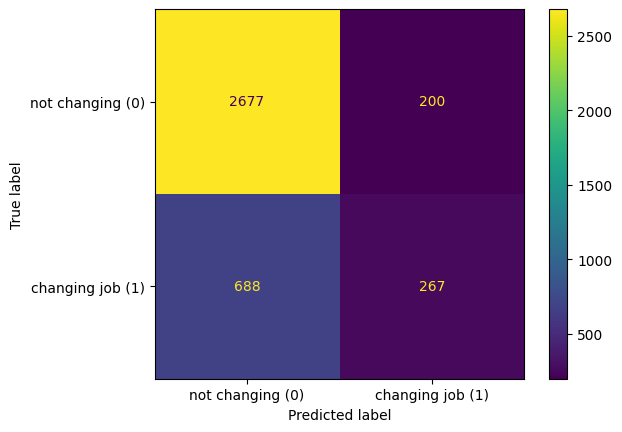

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    pipe, X_test, y_test, display_labels=["not changing (0)", "changing job (1)"]
);

### อ่านผลลัพธ์ให้เป็น

- accuracy ประมาณ 0.768 ดูดี แต่ baseline ก็ได้ 0.751 แล้ว โมเดลจึงดีกว่าการเดาเพียงเล็กน้อย
- recall ของคลาส 1 ประมาณ 0.28 คือโมเดลหาคนที่กำลังจะเปลี่ยนงานเจอเพียง 28% (ดูช่องล่างซ้ายของ confusion matrix: คนที่เปลี่ยนงานจริงแต่โมเดลทายว่าไม่เปลี่ยน)
- **ROC AUC** วัดว่าโมเดลเรียงลำดับคนที่จะเปลี่ยนงานไว้สูงกว่าคนที่ไม่เปลี่ยนได้ดีแค่ไหน ไม่ขึ้นกับ threshold และไม่ถูกหลอกด้วยข้อมูลไม่สมดุล ส่วนที่ 4 จึงใช้ ROC AUC เลือกโมเดล

### pipeline รับข้อมูลดิบได้โดยตรง

ข้อมูลด้านล่างมีทั้งข้อความและค่าว่าง (`NaN`) ส่งเข้า pipeline ได้เลย นี่คือคุณสมบัติที่ API ใน Lab 1.2 ต้องการ

In [16]:
raw = X_test.head(3)
display(raw)
print("ความน่าจะเป็นที่จะเปลี่ยนงาน:", pipe.predict_proba(raw)[:, 1].round(3))

,city_development_index,relevent_experience,experience,last_new_job,training_hours,gender,enrolled_university,education_level,major_discipline,company_size,company_type
686,0.939,Has relevent experience,12,1,42,NaN,no_enrollment,Graduate,STEM,1000-4999,Pvt Ltd
1106,0.698,No relevent experience,2,never,18,Female,Full time course,Graduate,STEM,NaN,NaN
8966,0.939,Has relevent experience,5,NaN,22,NaN,no_enrollment,High School,NaN,<10,Pvt Ltd


ความน่าจะเป็นที่จะเปลี่ยนงาน: [0.084 0.683 0.041]


### (เสริม) feature ใดมีผลต่อการทำนายมากที่สุด

ค่า coefficient ของ Logistic Regression: ค่าบวกเพิ่มโอกาสเปลี่ยนงาน ค่าลบลดโอกาส (เรื่องการอธิบายโมเดลจะเรียนละเอียดในบทที่ 7)

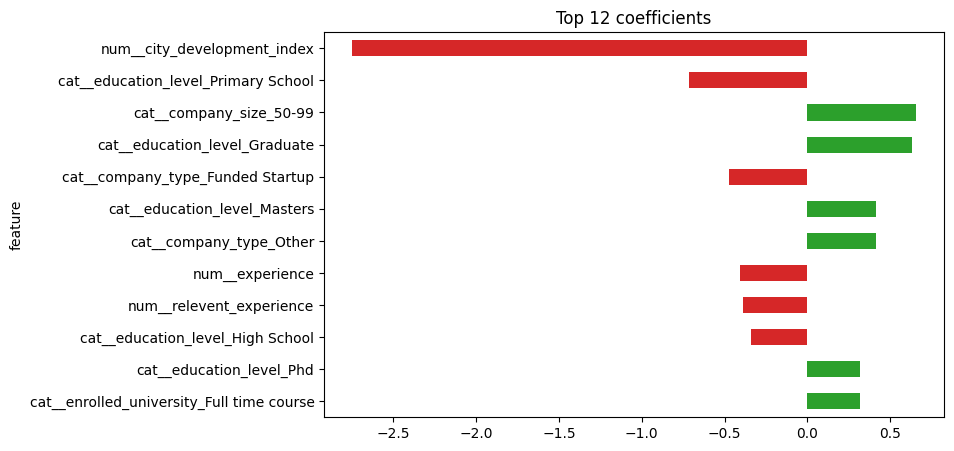

In [17]:
coef = pd.DataFrame({
    "feature": pipe.named_steps["col_trans"].get_feature_names_out(),
    "coef": pipe.named_steps["model"].coef_.ravel(),
})
top = coef.reindex(coef["coef"].abs().sort_values(ascending=False).index).head(12)
top.plot.barh(x="feature", y="coef", legend=False, figsize=(8, 5),
              color=["tab:green" if c > 0 else "tab:red" for c in top["coef"]],
              title="Top 12 coefficients").invert_yaxis()

✅ **Checkpoint 3:** ได้ accuracy ใกล้เคียง 0.77 และอธิบายได้ว่าทำไม accuracy 0.768 ไม่ได้แปลว่าโมเดลดี

---
## ส่วนที่ 4: ค้นหา preprocessing และโมเดลที่ดีที่สุดด้วย `GridSearchCV`

เพราะทุกขั้นอยู่ใน pipeline จึงค้นหาได้ทั้ง hyperparameter ของโมเดล **ทางเลือกของขั้นเตรียมข้อมูล** และ **ชนิดของโมเดล** ในครั้งเดียว

ชื่อ parameter ใน pipeline ใช้ `__` (ขีดล่าง 2 ตัว) คั่นแต่ละชั้น

In [18]:
[name for name in pipe.get_params() if name.startswith(("col_trans__num__", "model__"))][:15]

['col_trans__num__memory',
 'col_trans__num__steps',
 'col_trans__num__transform_input',
 'col_trans__num__verbose',
 'col_trans__num__impute',
 'col_trans__num__scale',
 'col_trans__num__impute__add_indicator',
 'col_trans__num__impute__copy',
 'col_trans__num__impute__fill_value',
 'col_trans__num__impute__keep_empty_features',
 'col_trans__num__impute__missing_values',
 'col_trans__num__impute__strategy',
 'col_trans__num__scale__clip',
 'col_trans__num__scale__copy',
 'col_trans__num__scale__feature_range']

- `col_trans__num__scale` = ขั้น `scale` ใน `num` pipeline ที่อยู่ใน `col_trans`
- `model__C` = parameter `C` ของโมเดล

ต่อไปจะลอง 2 ชุด: Logistic Regression (scaler 2 แบบ × ค่า C 5 ค่า) และ Random Forest (ความลึก 3 แบบ) แต่ละแบบทำ 5-fold cross-validation **(ใช้เวลาประมาณ 1–3 นาที)**

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler

param_grid = [
    {   # ชุดที่ 1: Logistic Regression
        "col_trans__num__scale": [MinMaxScaler(), StandardScaler()],
        "model": [LogisticRegression(max_iter=1000, random_state=0)],
        "model__C": [0.01, 0.1, 1, 10, 100],
    },
    {   # ชุดที่ 2: Random Forest
        "model": [RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)],
        "model__max_depth": [5, 10, None],
    },
]

# ใช้ ROC AUC แทน accuracy เพราะ target ไม่สมดุล
search = GridSearchCV(build_pipeline(), param_grid, scoring="roc_auc", cv=5, n_jobs=-1)
search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=0))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'col_trans__num__scale': [MinMaxScaler(), StandardScaler()], 'model': [LogisticRegre...andom_state=0)], 'model__C': [0.01, 0.1, ...]}, {'model': [RandomForestC...andom_state=0)], 'model__max_depth': [5, 10, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplex

In [20]:
results = pd.DataFrame(search.cv_results_)
results["model_name"] = results["param_model"].map(lambda m: type(m).__name__)
results["scaler"] = results["param_col_trans__num__scale"].map(
    lambda s: type(s).__name__ if not pd.isna(s) else "MinMaxScaler"
)
cols = ["model_name", "scaler", "param_model__C", "param_model__max_depth", "mean_test_score", "rank_test_score"]
results.sort_values("rank_test_score")[cols].head(8).round(4)

,model_name,scaler,param_model__C,param_model__max_depth,mean_test_score,rank_test_score
11,RandomForestClassifier,MinMaxScaler,NaN,10,0.7798,1
10,RandomForestClassifier,MinMaxScaler,NaN,5,0.7693,2
7,LogisticRegression,StandardScaler,1.0,NaN,0.7566,3
2,LogisticRegression,MinMaxScaler,1.0,NaN,0.7565,4
9,LogisticRegression,StandardScaler,100.0,NaN,0.7565,5
8,LogisticRegression,StandardScaler,10.0,NaN,0.7565,6
3,LogisticRegression,MinMaxScaler,10.0,NaN,0.7565,7
4,LogisticRegression,MinMaxScaler,100.0,NaN,0.7565,8


In [21]:
from sklearn.metrics import accuracy_score

best = search.best_estimator_
best_proba = best.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, best_proba)
test_acc = accuracy_score(y_test, best.predict(X_test))

print("พารามิเตอร์ที่ดีที่สุด:", search.best_params_)
print(f"ROC AUC (CV):    {search.best_score_:.3f}")
print(f"ROC AUC (test):  {test_auc:.3f}")
print(f"Accuracy (test): {test_acc:.3f}")

พารามิเตอร์ที่ดีที่สุด: {'model': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0), 'model__max_depth': 10}
ROC AUC (CV):    0.780
ROC AUC (test):  0.796
Accuracy (test): 0.780


**สิ่งที่ควรสังเกต**

- `param_grid` เป็น list ของ 2 dict เพื่อไม่ให้ลองค่าที่ไม่มีความหมาย เช่น ค่า `C` กับ Random Forest ซึ่งไม่มี parameter นี้
- เปลี่ยน scaler โดยใส่ object ใหม่แทนขั้น `col_trans__num__scale` และเปลี่ยนโมเดลโดยใส่ object ใหม่แทนขั้น `model`
- ใช้ ROC AUC จาก cross-validation บน train set **เลือก** โมเดล ส่วนตัวเลขจาก test set ใช้ **รายงานผล** เท่านั้น

**ส่วนที่ปรับจากบทความต้นฉบับ** (บทความเขียนในปี 2022)

| ในบทความ | ใน Lab นี้ | เหตุผล |
|---|---|---|
| `OneHotEncoder(sparse=False)` | `OneHotEncoder(sparse_output=False)` | ชื่อ parameter เปลี่ยนใน scikit-learn 1.2 |
| `get_feature_names()` | `get_feature_names_out()` | method เดิมถูกลบแล้ว |
| grid ของ `model__penalty: ['none', 'l2']` | grid ของ `model__C` อย่างเดียว | parameter `penalty` ถูกเลิกใช้ใน scikit-learn รุ่นใหม่ |
| แปลงค่าที่มีลำดับนอก pipeline, custom transformer สืบทอดเฉพาะ `TransformerMixin` | `OrdinalMapper` อยู่ใน pipeline และสืบทอด `BaseEstimator` ด้วย | ให้ API รับข้อมูลดิบได้ และ `GridSearchCV` clone ขั้นนี้ได้ถูกต้อง |
| class `ClfSwitcher` สำหรับสลับโมเดล | ใส่โมเดลแทนขั้น `model` ใน `param_grid` โดยตรง | scikit-learn รองรับอยู่แล้ว |
| `SVC` | `RandomForestClassifier` | `SVC` ช้ากับข้อมูลขนาดนี้ และไม่ให้ความน่าจะเป็นถ้าไม่ตั้ง `probability=True` |
| `scoring='accuracy'` | `scoring="roc_auc"` | ข้อมูลไม่สมดุล |

✅ **Checkpoint 4:** อธิบายได้ว่า `col_trans__num__scale` หมายถึงขั้นใด และทำไมเลือกโมเดลด้วย ROC AUC แทน accuracy

---
## ส่วนที่ 5: บันทึก pipeline และดาวน์โหลดไฟล์

บันทึก **ทั้ง pipeline** (การเตรียมข้อมูล + โมเดล) เป็นไฟล์เดียว พร้อม `metadata.json` ที่บอกว่าโมเดลมาจากไหน ได้คะแนนเท่าไร และสร้างด้วย scikit-learn เวอร์ชันใด API ใน Lab 1.2 จะแสดงข้อมูลนี้ที่ `GET /model-info`

In [22]:
import json
from datetime import datetime, timezone
from pathlib import Path

import joblib

Path("model").mkdir(exist_ok=True)
joblib.dump(best, "model/pipe.joblib")

metadata = {
    "model_version": datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S"),
    "model": type(best.named_steps["model"]).__name__,
    "best_params": {k: str(v) for k, v in search.best_params_.items()},
    "cv_roc_auc": round(search.best_score_, 4),
    "test_roc_auc": round(test_auc, 4),
    "test_accuracy": round(test_acc, 4),
    "features": FEATURES,
    "sklearn_version": sklearn.__version__,
}
Path("model/metadata.json").write_text(json.dumps(metadata, indent=2))
print(json.dumps(metadata, indent=2))

{
  "model_version": "20261031-085832",
  "model": "RandomForestClassifier",
  "best_params": {
    "model": "RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0)",
    "model__max_depth": "10"
  },
  "cv_roc_auc": 0.7798,
  "test_roc_auc": 0.7957,
  "test_accuracy": 0.78,
  "features": [
    "city_development_index",
    "relevent_experience",
    "experience",
    "last_new_job",
    "training_hours",
    "gender",
    "enrolled_university",
    "education_level",
    "major_discipline",
    "company_size",
    "company_type"
  ],
  "sklearn_version": "1.9.1"
}


ทดสอบโหลดกลับมาใช้ ต้องทำนายได้ผลเท่าเดิม

In [23]:
loaded = joblib.load("model/pipe.joblib")
print("โหลดโมเดลกลับมาแล้วทำนายได้ผลเท่าเดิม:", np.allclose(loaded.predict_proba(X_test)[:, 1], best_proba))

โหลดโมเดลกลับมาแล้วทำนายได้ผลเท่าเดิม: True


รวม `features.py` และโฟลเดอร์ `model/` เป็นไฟล์ zip แล้วดาวน์โหลด (ถ้าเบราว์เซอร์ถามว่าอนุญาตให้ดาวน์โหลดหลายไฟล์หรือไม่ ให้กด **Allow**)

ถ้าดาวน์โหลดอัตโนมัติไม่ทำงาน: เปิดแถบ **Files** (ไอคอนโฟลเดอร์ด้านซ้าย) → คลิกขวาที่ `bd532_lab1_artifacts.zip` → **Download**

In [24]:
!zip -q -r bd532_lab1_artifacts.zip features.py model
!unzip -l bd532_lab1_artifacts.zip

try:
    from google.colab import files
    files.download("bd532_lab1_artifacts.zip")
except ImportError:
    print("ไม่ได้รันบน Colab: ไฟล์อยู่ที่", Path("bd532_lab1_artifacts.zip").resolve())

Archive:  bd532_lab1_artifacts.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
     3206  2026-10-31 08:57   features.py
        0  2026-10-31 08:58   model/
      584  2026-10-31 08:58   model/metadata.json
 11088443  2026-10-31 08:58   model/pipe.joblib
---------                     -------
 11092233                     4 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ **Checkpoint 5:** มีไฟล์ `bd532_lab1_artifacts.zip` บนเครื่อง ภายในมี `features.py`, `model/pipe.joblib` และ `model/metadata.json`

---
## (ไม่บังคับ) ลองทำเอง

1. **ปรับ threshold:** โมเดลทายว่า "เปลี่ยนงาน" เมื่อความน่าจะเป็น ≥ 0.5 ลองใช้ `(best_proba >= 0.3).astype(int)` แล้วดู `classification_report` ว่า recall และ precision ของคลาส 1 เปลี่ยนไปอย่างไร ถ้าบริษัทอยากหาคนที่จะลาออกให้ได้มากที่สุด ควรตั้ง threshold เท่าไร
2. **เพิ่มทางเลือกของการเติมค่าว่าง:** เพิ่ม `"col_trans__num__impute__strategy": ["mean", "median"]` ใน dict ชุดที่ 1 ของ `param_grid` แล้วรัน grid search ใหม่
3. **`company_size` มีลำดับหรือไม่:** ค่าของ `company_size` (`<10`, `10/49`, ..., `10000+`) มีลำดับ ลองเพิ่มตารางแปลงใน `ORDINAL_MAPS` และย้ายคอลัมน์นี้จาก `CAT_COLS` ไป `NUM_COLS` (อย่าลืมรันเซลล์ `%%writefile` ใหม่ และ **Runtime → Restart session** เพื่อให้ import ไฟล์ใหม่) แล้วดูว่า ROC AUC ดีขึ้นหรือไม่

---
## สรุปและขั้นต่อไป

- `Pipeline` และ `ColumnTransformer` รวมการเตรียมข้อมูลและโมเดลไว้ใน object เดียว ป้องกัน data leakage และทำให้ deploy ง่าย
- custom transformer ต้องอยู่ในไฟล์ `.py` แยก เพื่อให้โหลดโมเดลในโปรแกรมอื่นได้
- ใช้ metric ที่เหมาะกับปัญหา (ROC AUC, recall) และเทียบกับ baseline เสมอ

**Lab 1.2:** นำ `bd532_lab1_artifacts.zip` ไปเปิดให้บริการเป็น API ด้วย FastAPI ใน GitHub Codespaces ตามคู่มือ Lab สัปดาห์ที่ 1